# Семинар 9: автокодировщики

Как будто бы все предыдущие 8 существуют...

Энивей, спасибо Марку Блуменау (@markblumenau) за почти всю тетрадку!

## 1. Введение 

Автоэнкодеры – это unsupervised (не требующие разметки для обучения) модели, которые находят применение как базовые строительные блоки в огромном количестве сложных моделей.

Идея автоэнкодера крайне проста. 

Он состоит из двух моделей называемых _энкодером_ и _декодером_, которые работают в тандеме. 

Задача энкодера – сжать исходный объект до вектора малой размерности, называемого _латентным кодом_. 

Задача декодера – восстановить из этого латентного кода исходный объект. 

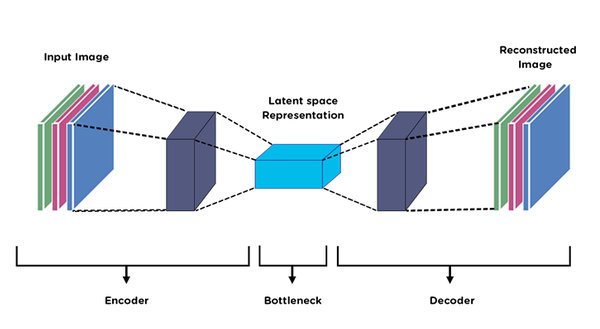

---
Обучение происходит путем уменьшения ошибки между исходным объектом и восстановленным:

$$ 
Loss = 
\sum_{x_i \in X} MSE(x_i, x_i') =
\sum_{x_i \in X} MSE(x_i, f_{\theta}(g_{\phi}(x_i)))
$$



In [2]:
from typing import Type, Union

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
from torch import nn, optim


torch.manual_seed(7)
np.random.seed(7)
torch.set_num_threads(2)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

Устройство: NVIDIA GeForce RTX 3070 Ti Laptop GPU


In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.functional import interpolate

DATASET = "digits"  # "mnist" для полной базы MNIST
if DATASET == "digits":
    digits = load_digits()
    images = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
    images = interpolate(images, size=(28, 28), mode="bilinear", align_corners=False)
    targets = torch.tensor(digits.target, dtype=torch.long)
    train_ids, test_ids = train_test_split(np.arange(len(images)), stratify=targets,
                                           test_size=0.2, random_state=7)
    train_dataset = TensorDataset(images[train_ids], targets[train_ids])
    test_dataset = TensorDataset(images[test_ids], targets[test_ids])
elif DATASET == "mnist":
    train_dataset, test_dataset = [
        torchvision.datasets.MNIST("./mnist", train=split, download=True,
                                   transform=transforms.ToTensor()) for split in (True, False)
    ]
else:
    raise ValueError("Выберите digits или mnist")

train_dataloader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=256)
print(DATASET, len(train_dataset), "обучающих,", len(test_dataset), "тестовых изображений")

digits 1437 обучающих, 360 тестовых изображений


## 1.1. PCA как простейший автокодировщик

k= 2   доля дисперсии на train: 32.0%   MSE на test: 0.0324
k= 8   доля дисперсии на train: 74.1%   MSE на test: 0.0123
k=32   доля дисперсии на train: 98.3%   MSE на test: 0.0009


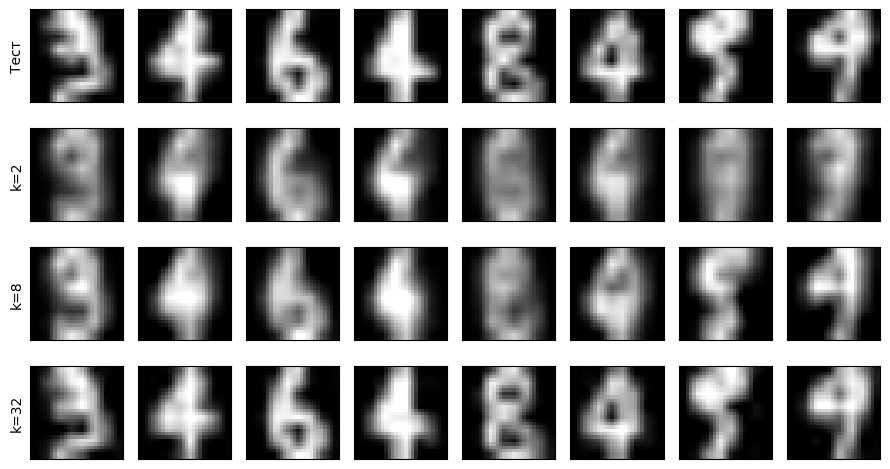

In [57]:
from sklearn.decomposition import PCA
def pixel_matrix(dataset, limit):
    loader = DataLoader(dataset, batch_size=min(limit, len(dataset)), shuffle=False)
    x, y = next(iter(loader))
    return x.flatten(1).numpy(), y.numpy()

X_train, _ = pixel_matrix(train_dataset, 6000)
X_test, y_test = pixel_matrix(test_dataset, 1000)
pca = PCA(n_components=32, svd_solver="randomized", random_state=7).fit(X_train)
scores = pca.transform(X_test)
def restore(k):
    return scores[:, :k] @ pca.components_[:k] + pca.mean_

fig, axes = plt.subplots(4, 8, figsize=(9, 5))
for row, (label, batch) in enumerate([("Тест", X_test)] + [(f"k={k}", restore(k)) for k in (2, 8, 32)]):
    for col, ax in enumerate(axes[row]):
        ax.imshow(batch[col].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(label)
plt.tight_layout()
for k in (2, 8, 32):
    print(f"k={k:2d}   доля дисперсии на train: {pca.explained_variance_ratio_[:k].sum():.1%}"
          f"   MSE на test: {np.mean((X_test - restore(k))**2):.4f}")

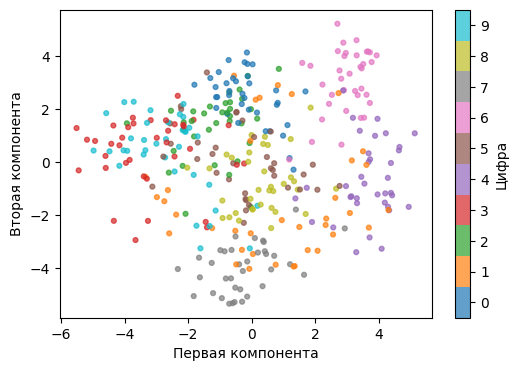

In [58]:
fig, ax = plt.subplots(figsize=(6, 4))
points = ax.scatter(*scores[:, :2].T, c=y_test, cmap="tab10", vmin=-0.5, vmax=9.5, s=12, alpha=.7)
fig.colorbar(points, ticks=range(10), label="Цифра")
ax.set(xlabel="Первая компонента", ylabel="Вторая компонента")
plt.show()

## 2. AE для MNIST

Давайте реализуем простейший автоэнкодер, который берет изображения размера **28 × 28** и кодирует их в латентный код длины **k**. 

В этой части надо реализовать:

* Encoder
    * Четырехслойная полносвязная сеть с размерностями (784-128-64-k)
* Decoder
    * Симметричная полносвязная сеть с размерностями (k-64-128-784)
* Loss функцию для обучения
    * L2 между входом и выходом автоэнкодера

In [6]:
class MNISTEncoder(nn.Module):
    def __init__(self, lat_size: int = 10) -> None:
        super().__init__()

        self.lat_size = lat_size

        # YOUR CODE HERE
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, self.lat_size),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.encoder(x)

        return z


class MNISTDecoder(nn.Module):
    def __init__(self, lat_size: int = 10) -> None:
        super().__init__()

        self.lat_size = lat_size

        # YOUR CODE HERE
        self.decoder = nn.Sequential(
            nn.Linear(self.lat_size, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        reconstructed_x = self.decoder(z)
        reconstructed_x = reconstructed_x.view(-1, 1, 28, 28)

        return reconstructed_x

In [7]:
class AutoEncoder(nn.Module):
    def __init__(
        self,
        lat_size: int = 10,
        encoder_class: Type[MNISTEncoder] = MNISTEncoder,
        decoder_class: Type[MNISTDecoder] = MNISTDecoder,
        criterion_class: Type[torch.optim.Optimizer] = nn.MSELoss,
    ) -> None:
        super().__init__()

        self.lat_size = lat_size
        self.enc = encoder_class(lat_size)
        self.dec = decoder_class(lat_size)
        self.criterion = criterion_class()

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def compute_loss(
        self, x: torch.Tensor, return_reconstruction: bool = False
    ) -> Union[tuple[torch.Tensor, torch.Tensor], torch.Tensor]:
        z = self.encode(x)  # YOUR CODE HERE
        reconstructed_x = self.decode(z)  # YOUR CODE HERE

        loss = self.criterion(x, reconstructed_x)

        if return_reconstruction:
            return loss, reconstructed_x
        else:
            return loss

In [8]:
from IPython.display import clear_output, display


def train_model(model, train_dataloader, optimizer, num_epochs=None, device=device,
                conditional=False, preview_noise=None):
    model.to(device)
    if num_epochs is None:
        num_epochs = 30 if DATASET == 'digits' else 5

    # Один набор тестовых цифр для сравнения реконструкций между эпохами.
    samples = [test_dataset[i] for i in range(8)]
    original = torch.stack([image for image, _ in samples])
    labels = torch.tensor([int(label) for _, label in samples], device=device)
    preview = original
    if preview_noise is not None:
        with torch.random.fork_rng(devices=[]):
            torch.random.default_generator.manual_seed(7)
            preview = preview_noise(original.clone())
    preview = preview.to(device)

    row_names = ["Оригинал", "Реконструкция"]
    if preview_noise is not None:
        row_names.insert(1, "С шумом")
    fig = plt.figure(figsize=(10, 3.6))
    plt.close(fig)  # Показываем один кадр явно при каждом обновлении.
    layout = fig.add_gridspec(len(row_names), 2, width_ratios=[1, 2.5])
    curve = fig.add_subplot(layout[:, 0])
    (line,) = curve.plot([], [], marker=".", color="teal")
    curve.set(xlabel="Эпоха", ylabel="Средние потери", xlim=(0, num_epochs))
    panels = []
    for row, name in enumerate(row_names):
        ax = fig.add_subplot(layout[row, 1])
        ax.set_ylabel(name, rotation=0, ha="right", va="center")
        ax.set_xticks([])
        ax.set_yticks([])
        panels.append(ax)
    fig.subplots_adjust(left=.09, right=.99, bottom=.16, top=.86, wspace=.6)
    steps, history = [], []

    @torch.no_grad()
    def update_plot(step, mean_loss, caption):
        model.eval()
        args = (labels,) if conditional else ()
        code = model.encode(preview, *args)
        if isinstance(code, tuple):
            code = code[0]  # Для VAE и CVAE сравниваем реконструкции по среднему коду.
        restored = model.decode(code, *args)
        batches = [original, restored]
        if preview_noise is not None:
            batches.insert(1, preview)
        for ax, batch in zip(panels, batches):
            strip = torch.cat(list(batch[:, 0].detach().cpu()), dim=1)
            if ax.images:
                ax.images[0].set_data(strip)
            else:
                ax.imshow(strip, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        steps.append(step)
        history.append(mean_loss)
        line.set_data(steps, history)
        curve.relim()
        curve.autoscale_view(scalex=False)
        fig.suptitle(f"{caption}   ·   Средние потери {mean_loss:.4f}")
        clear_output(wait=True)
        display(fig)
        model.train()

    for epoch in range(num_epochs):
        model.train()
        total, seen = 0.0, 0
        for batch_index, (x, y) in enumerate(train_dataloader):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = model.compute_loss(x, y) if conditional else model.compute_loss(x)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
            seen += len(x)
            if epoch == 0 and batch_index == 0 and len(train_dataloader) > 1:
                update_plot(1 / len(train_dataloader), total / seen, "Первый батч")
        update_plot(epoch + 1, total / seen, f"Эпоха {epoch + 1} из {num_epochs}")
    model.eval()

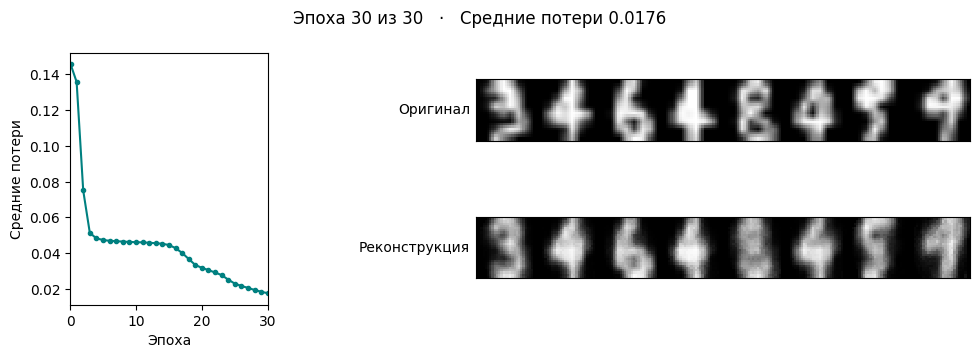

In [9]:
# обучим модель с латентным кодом длины 8
model = AutoEncoder(8).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

train_model(model, train_dataloader, optimizer, device=device)

## 3. Структура и интерпретация латентного пространства

Главная ценность автоэнкодера как модели - его латентный код. 

Он крайне насыщенный, т.к. он должен сохранять как можно больше важной информации об объекте. 

Кроме того, само латентное пространство (множество латентных кодов всех объектов) - сохраняет структуру исходного пространства - например, похожие объекты в исходном пространстве будут находиться недалеко друг от друга в латентном пространстве. 

В этой части мы проиллюстрируем эти свойства.

### 3.1 Интерполяция латентных кодов

Обычно интерполируют по прямой - соединяют две точки, соответсвующие реальным объектам, отрезком и смотрят латентные коды через равные части этого отрезка. Для каждой промежуточной точки строят выход декодера. 

Давайте возьмем два случайных объекта из выборки и построим интерполяцию между ними.

In [10]:
x, _ = next(iter(train_dataloader))

x1 = x[0].to(device)
x2 = x[1].to(device)

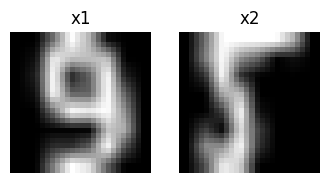

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(4, 2))

axs[0].axis("off")
axs[0].set_title("x1")
axs[0].imshow(x1[0].cpu().detach().numpy(), cmap="gray")
axs[1].axis("off")
axs[1].set_title("x2")
axs[1].imshow(x2[0].cpu().detach().numpy(), cmap="gray");

In [12]:
# получите латентные коды объектов
# YOUR CODE HERE
z_1 = model.encode(x1[None, :, :, :])
z_2 = model.encode(x2[None, :, :, :])

# постройте батч с интерполяцией этих латентных кодов по прямой в 11 точках (используйте функцию torch.linspace)
# YOUR CODE HERE
linspace = torch.linspace(0, 1, 11)[:, None].to(device)
z_linspace = z_2 * linspace + z_1 * (1 - linspace)

# восстановите для всех латентных кодов изображения
# YOUR CODE HERE
x_linspace = model.decode(z_linspace)

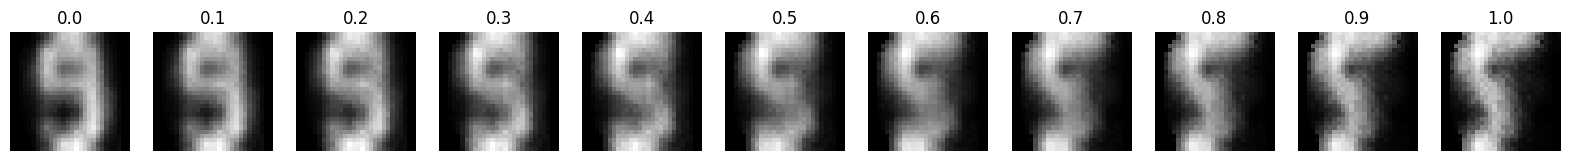

In [13]:
# нарисуем проинтерполированные объекты
fig, axs = plt.subplots(1, 11, figsize=(20, 20))

for i, d in enumerate(np.linspace(0, 1, 11)):
    axs[i].axis("off")
    axs[i].set_title(f"{d:.2}")
    axs[i].imshow(x_linspace[i, 0].cpu().detach().numpy(), cmap="gray")

### 3.2 Структура латентного пространства

Теперь давайте обучим автоэнкодер с **2** латентными кодами, соберем эти латентные коды и нарисуем 2d plot, где латентные коды подсвечены цветами классов исходных объектов.

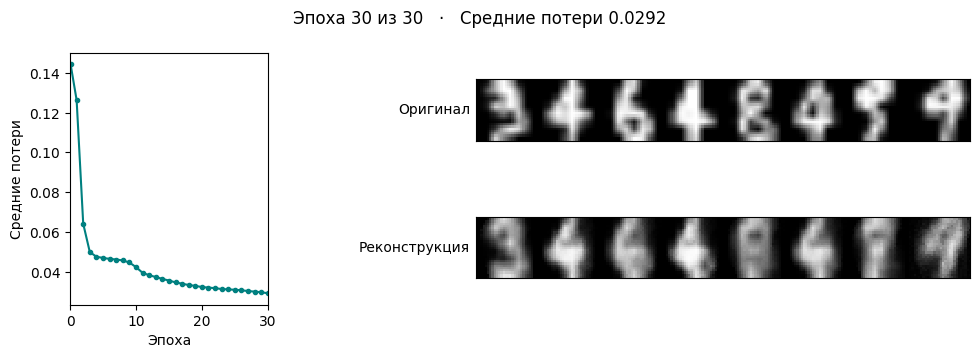

In [54]:
# обучим автоэнкодер с 2 латентными кодами
model_2d = AutoEncoder(2).to(device)
optimizer = optim.Adam(model_2d.parameters(), lr=1e-3)
train_model(model_2d, train_dataloader, optimizer, device=device)

In [16]:
def get_latent_codes_and_labels(
    dataloader: torch.utils.data.DataLoader, model: nn.Module, num_objects: int
) -> tuple[torch.Tensor, torch.Tensor]:
    lat_codes = torch.empty((0, model.lat_size)).to(device)
    labels = torch.empty(0).to(device)

    for batch in dataloader:
        x, y = batch
        x, y = x.to(device), y.to(device)
        cur_lat_codes = model.encode(x)

        lat_codes = torch.cat((lat_codes, cur_lat_codes), dim=0)
        labels = torch.cat((labels, y), dim=0)

        if lat_codes.shape[0] >= num_objects:
            break
    lat_codes = lat_codes[:num_objects].detach().cpu().numpy()
    labels = labels[:num_objects].detach().cpu().numpy()

    return lat_codes, labels


# соберем для 1000 случайных объектов их латентные коды и классы
lat_codes, labels = get_latent_codes_and_labels(train_dataloader, model_2d, 1000)

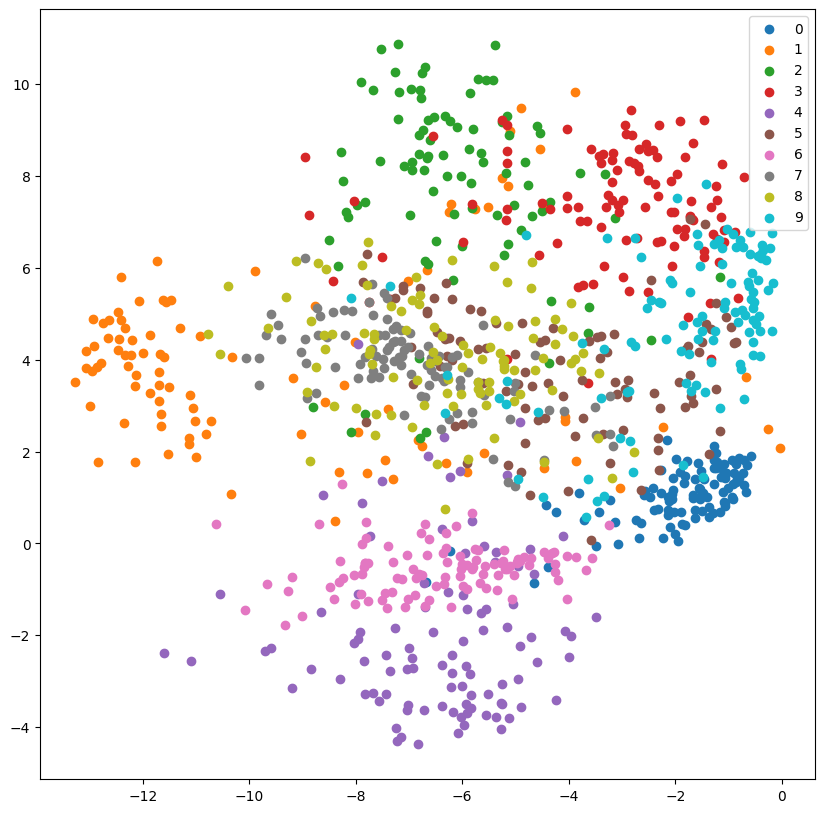

In [17]:
plt.figure(figsize=(10, 10))

for cl in range(10):
    lat_codes_class = lat_codes[labels == cl]
    plt.scatter(lat_codes_class[:, 0], lat_codes_class[:, 1], label=f"{cl}")
plt.legend()
plt.show()

### 3.3 Структура латентного пространства 2.0

А теперь давайте обучим автоэнкодер с **32** латентными кодами, а потом сожмем до размемрности **2** с помощью **t-sne**.

In [18]:
from sklearn.manifold import TSNE

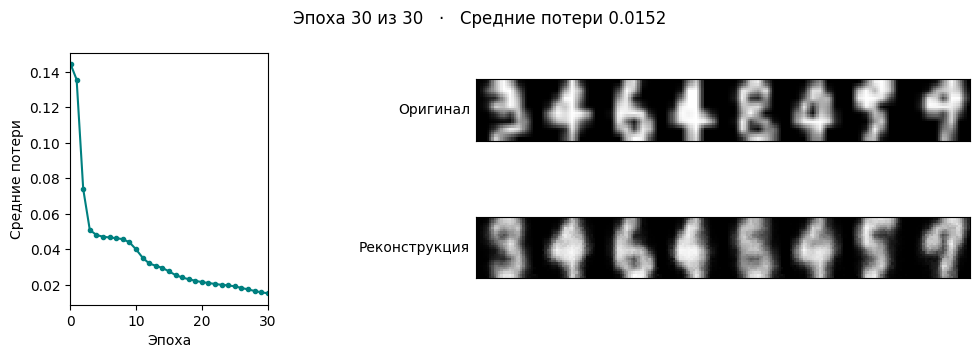

In [55]:
model_big = AutoEncoder(32).to(device)
optimizer = optim.Adam(model_big.parameters(), lr=1e-3)
train_model(model_big, train_dataloader, optimizer, device=device)

In [20]:
tsne = TSNE(n_components=2, random_state=7)
lat_codes, labels = get_latent_codes_and_labels(train_dataloader, model_big, 1000)
new_codes = tsne.fit_transform(lat_codes)

c:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^

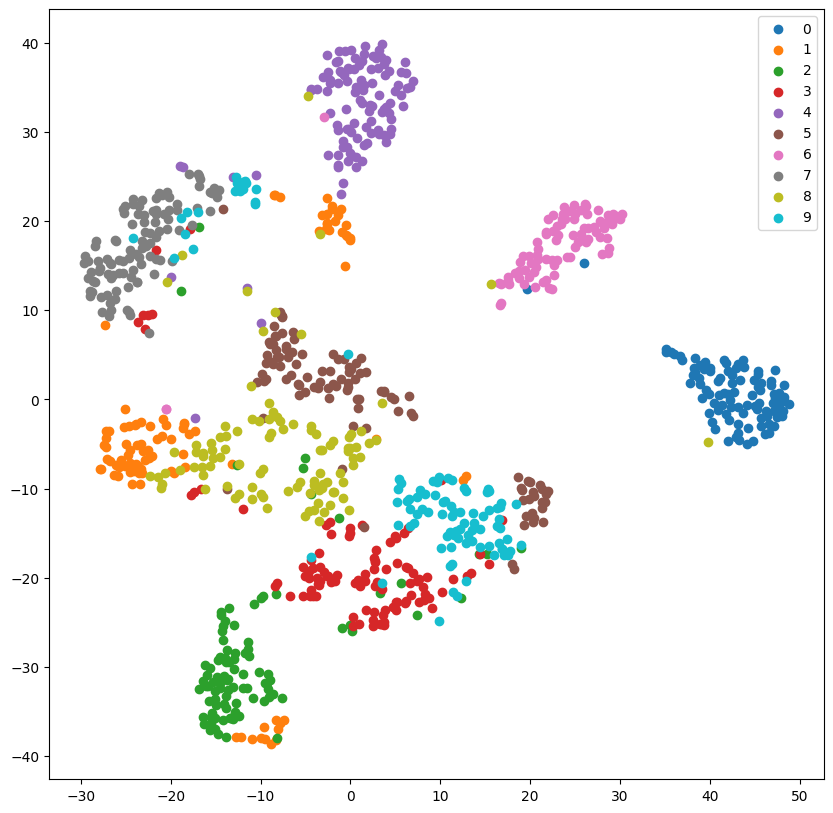

In [21]:
plt.figure(figsize=(10, 10))

for cl in range(10):
    lat_codes_class = new_codes[labels == cl]
    plt.scatter(lat_codes_class[:, 0], lat_codes_class[:, 1], label=f"{cl}")

plt.legend()
plt.show()

## 4. Удаление шума

С вероятностью 0,1 заменим значение пикселя $u$ на $1-u$. Входом будет искажённая цифра, целью останется исходная. Сравним их попарно на тестовых объектах.

In [22]:
def corrupt(x):
    return torch.where(torch.rand_like(x) < 0.1, 1 - x, x)

class DenoisingAE(AutoEncoder):
    def compute_loss(self, clean, return_reconstruction=False):
        reconstruction = self.decode(self.encode(corrupt(clean)))
        loss = self.criterion(clean, reconstruction)
        return (loss, reconstruction) if return_reconstruction else loss

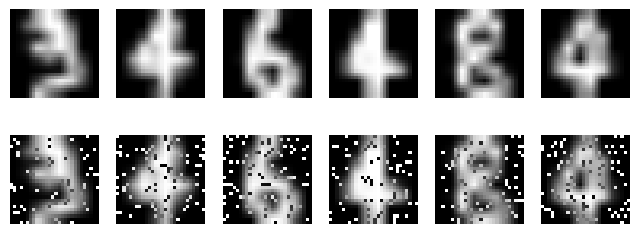

In [23]:
clean, _ = next(iter(test_dataloader))
x = corrupt(clean)
fig, axes = plt.subplots(2, 6, figsize=(8, 3))
for col in range(6):
    for row, batch in enumerate([clean, x]):
        axes[row, col].imshow(batch[col, 0], cmap="gray")
        axes[row, col].axis("off")

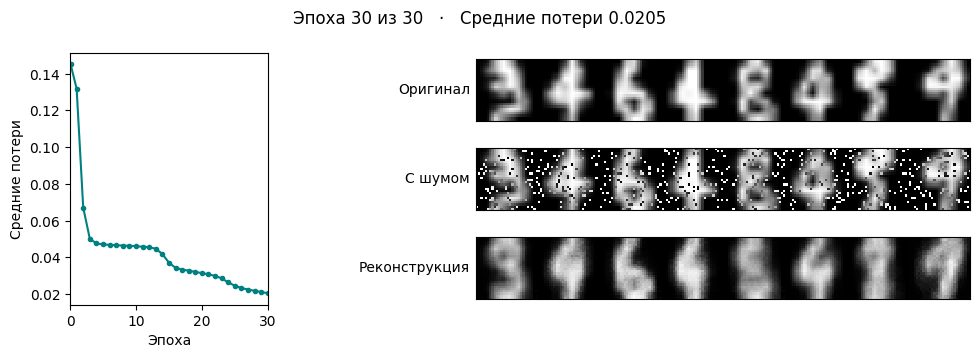

In [56]:
# обучим автоэнкодер на зашумленных данных
model_for_noise = DenoisingAE(64).to(device)
optimizer = optim.Adam(model_for_noise.parameters(), lr=1e-3)
train_model(model_for_noise, train_dataloader, optimizer, device=device, preview_noise=corrupt)

In [25]:
with torch.no_grad():
    reconstructed_x = model_for_noise.decode(model_for_noise.encode(x.to(device)))

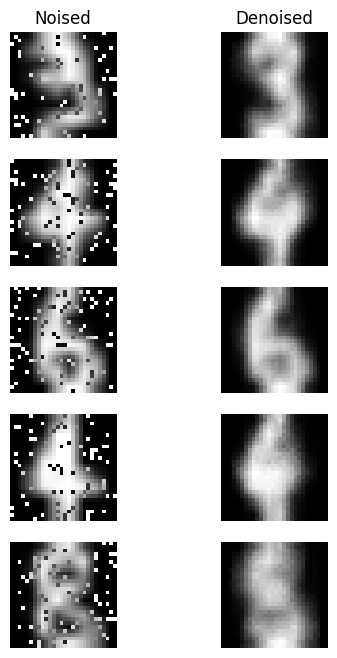

In [26]:
fig, axs = plt.subplots(5, 2, figsize=(5, 8))

for i, (ax, noised, denoised) in enumerate(zip(axs, x[:10], reconstructed_x[:10])):
    ax[0].imshow(noised[0].cpu().detach().numpy(), cmap="gray")
    ax[1].imshow(denoised[0].cpu().detach().numpy(), cmap="gray")
    ax[0].axis("off")
    ax[1].axis("off")
    if i == 0:
        ax[0].set_title(f"Noised")
        ax[1].set_title(f"Denoised")

In [27]:
x, y = next(iter(test_dataloader))
_, reconstructed_x = model_for_noise.compute_loss(x.to(device), return_reconstruction=True)

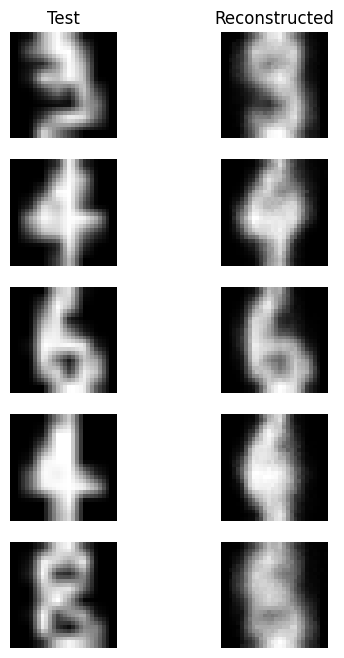

In [28]:
fig, axs = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(5, 8),
)

for i, (ax, noised, denoised) in enumerate(zip(axs, x[:10], reconstructed_x[:10])):
    ax[0].imshow(noised[0].cpu().detach().numpy(), cmap="gray")
    ax[1].imshow(denoised[0].cpu().detach().numpy(), cmap="gray")
    ax[0].axis("off")
    ax[1].axis("off")
    if i == 0:
        ax[0].set_title(f"Test")
        ax[1].set_title(f"Reconstructed")

## 5. Variational AE

Для каждой цифры энкодер возвращает $\mu$ и $s=\log\sigma^2$. 

Они задают $q_\phi(z\mid x)$, диагональную нормальную аппроксимацию апостериорного распределения.

Выбираем $p(z)=\mathcal N(0,I)$. (это наш прайор, можно провести аналогию с тем, как мы задавали его в линейной регрессии и получали регуляризацию)

Мы как бы предполагаем, что наше латентное простанство очень плотное и сконцентрировано где-то в начале координат (а почему и нет, сэмплы оч удобно было бы брать)

Сэмпл из энкодера получаем как $z=\mu+\exp(s/2)\odot\varepsilon$, где $\varepsilon\sim\mathcal N(0,I)$.

Декодер задаёт среднее $m_\theta(z)$ нормальной модели пикселей с фиксированной дисперсией $\tau^2=0.25$ (выбрали по приколу). 

Для одного изображения минимизируем оценку отрицательной ELBO (константу опускаем):

$$
\frac{\|x-m_\theta(z)\|^2}{2\tau^2}+
\frac12\sum_j\big(\mu_j^2+\exp(s_j)-1-s_j\big).
$$

Первое слагаемое оцениваем по одной реализации шума. 
Второе считаем точно. 

Суммируем по пикселям и скрытым координатам, затем усредняем по изображениям батча.

In [59]:
class MNISTEncoder_vae(nn.Module):
    def __init__(self, lat_size: int):
        super().__init__()

        self.lat_size = lat_size

        self.enc = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU()
        )

        self.mu = nn.Linear(256, self.lat_size)
        self.logvar = nn.Linear(256, self.lat_size)

    def forward(self, x: torch.Tensor):
        # YOUR CODE HERE
        z = self.enc(x)
        mu, logvar = self.mu(z), self.logvar(z)

        return mu, logvar


class MNISTDecoder_vae(nn.Module):
    def __init__(self, lat_size: int):
        super().__init__()

        self.lat_size = lat_size

        self.dec = nn.Sequential(
            nn.Linear(self.lat_size, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid()
        )

    def forward(self, z: torch.Tensor):
        x_reconstructed = self.dec(z)
        x_reconstructed = x_reconstructed.view(-1, 1, 28, 28)

        return x_reconstructed

In [60]:
class VariationalAutoEncoder(nn.Module):
    def __init__(
        self,
        lat_size: int,
        KL_weight: float = 1.0,
        encoder_class: Type[MNISTEncoder_vae] = MNISTEncoder_vae,
        decoder_class: Type[MNISTDecoder_vae] = MNISTDecoder_vae,
        criterion_class: Type[nn.MSELoss] = nn.MSELoss,
    ) -> None:
        super().__init__()

        self.lat_size = lat_size
        self.enc = encoder_class(lat_size)
        self.dec = decoder_class(lat_size)
        self.criterion = criterion_class()
        
        self.KL_weight = KL_weight

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.enc(x)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.dec(z)

    def sample_z(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        eps = torch.randn(mu.size(), device=mu.device)  # YOUR CODE HERE

        return mu + torch.exp(logvar / 2) * eps

    def custom_loss(
        self,
        x: torch.Tensor,
        reconstructed_x: torch.Tensor,
        mu: torch.Tensor,
        logvar: torch.Tensor,
    ) -> torch.Tensor:
        KL = torch.mean(
            -0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp(), dim=1), dim=0
        )
        reconstruction_loss = ((x - reconstructed_x).flatten(1).square().sum(1) / (2 * 0.25)).mean()

        return KL * self.KL_weight + reconstruction_loss

    def compute_loss(
        self, x: torch.Tensor, return_reconstruction: bool = False
    ) -> Union[tuple[torch.Tensor, torch.Tensor], torch.Tensor]:
        mu, logvar = self.encode(x)
        z = self.sample_z(mu, logvar)
        reconstructed_x = self.decode(z)

        loss = self.custom_loss(x, reconstructed_x, mu, logvar)

        if return_reconstruction:
            return loss, reconstructed_x
        else:
            return loss

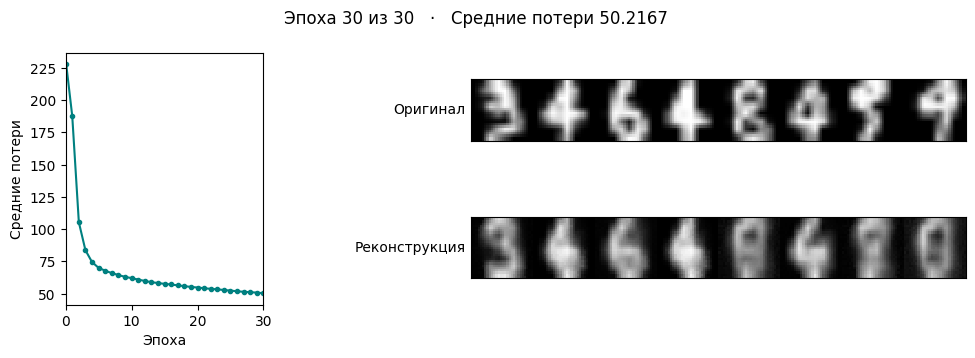

In [61]:
hidden_dim = 2
model_vae = VariationalAutoEncoder(hidden_dim).to(device)
optimizer = optim.Adam(model_vae.parameters(), lr=1e-3)

train_model(model_vae, train_dataloader, optimizer)

### 5.1 Interpolation of latent codes

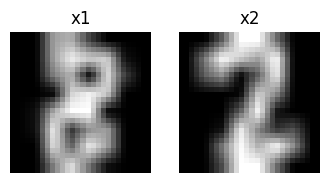

In [77]:
x, _ = next(iter(train_dataloader))

x1 = x[0].to(device)
x2 = x[1].to(device)
fig, axs = plt.subplots(1, 2, figsize=(4, 2))

axs[0].axis("off")
axs[0].set_title("x1")
axs[0].imshow(x1[0].cpu().detach().numpy(), cmap="gray")
axs[1].axis("off")
axs[1].set_title("x2")
axs[1].imshow(x2[0].cpu().detach().numpy(), cmap="gray");

In [78]:
# получите латентные коды объектов
z_1_mu, z_1_logs = model_vae.encode(x1[None, :, :, :])
z_2_mu, z_2_logs = model_vae.encode(x2[None, :, :, :])
z_1 = model_vae.sample_z(z_1_mu, z_1_logs)
z_2 = model_vae.sample_z(z_2_mu, z_2_logs)

# постройте батч с интерполяцией этих латентных кодов по прямой в 11 точках (используйте функцию torch.linspace)
linspace = torch.linspace(0, 1, 11)[:, None].to(device)
z_linspace = z_2 * linspace + z_1 * (1 - linspace)

# восстановите для всех латентных кодов изображения
x_linspace = model_vae.decode(z_linspace)

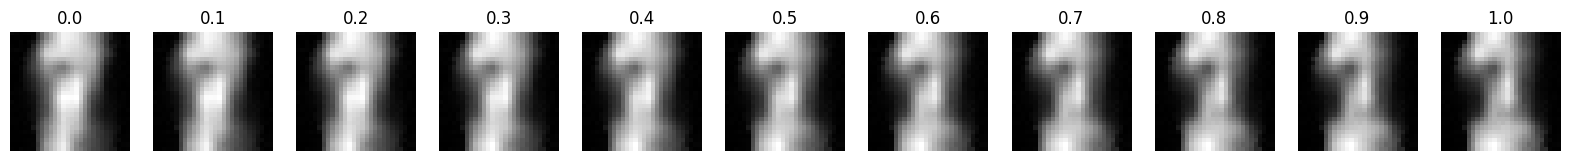

In [79]:
# нарисуем проинтерполированные объекты
fig, axs = plt.subplots(1, 11, figsize=(20, 20))

for i, d in enumerate(np.linspace(0, 1, 11)):
    axs[i].axis("off")
    axs[i].set_title(f"{d:.2}")
    axs[i].imshow(x_linspace[i, 0].cpu().detach().numpy(), cmap="gray")

### 5.2 Структура латентного пространства

In [80]:
def get_latent_codes_and_labels_vae(
    dataloader: torch.utils.data.DataLoader, model: nn.Module, num_objects: int
) -> tuple[torch.Tensor, torch.Tensor]:
    lat_codes = torch.empty((0, model.lat_size)).to(device)
    labels = torch.empty(0).to(device)

    for batch in dataloader:
        x, y = batch
        x, y = x.to(device), y.to(device)
        cur_lat_mean, cur_lat_var = model.encode(x)

        eps = torch.randn(cur_lat_mean.shape).to(device)
        cur_lat_codes = cur_lat_mean + torch.exp(cur_lat_var / 2) * eps

        lat_codes = torch.cat((lat_codes, cur_lat_codes), dim=0)
        labels = torch.cat((labels, y), dim=0)

        if lat_codes.shape[0] >= num_objects:
            break
    lat_codes = lat_codes[:num_objects].detach().cpu().numpy()
    labels = labels[:num_objects].detach().cpu().numpy()

    return lat_codes, labels

In [81]:
lat_codes, labels = get_latent_codes_and_labels_vae(train_dataloader, model_vae, 1000)

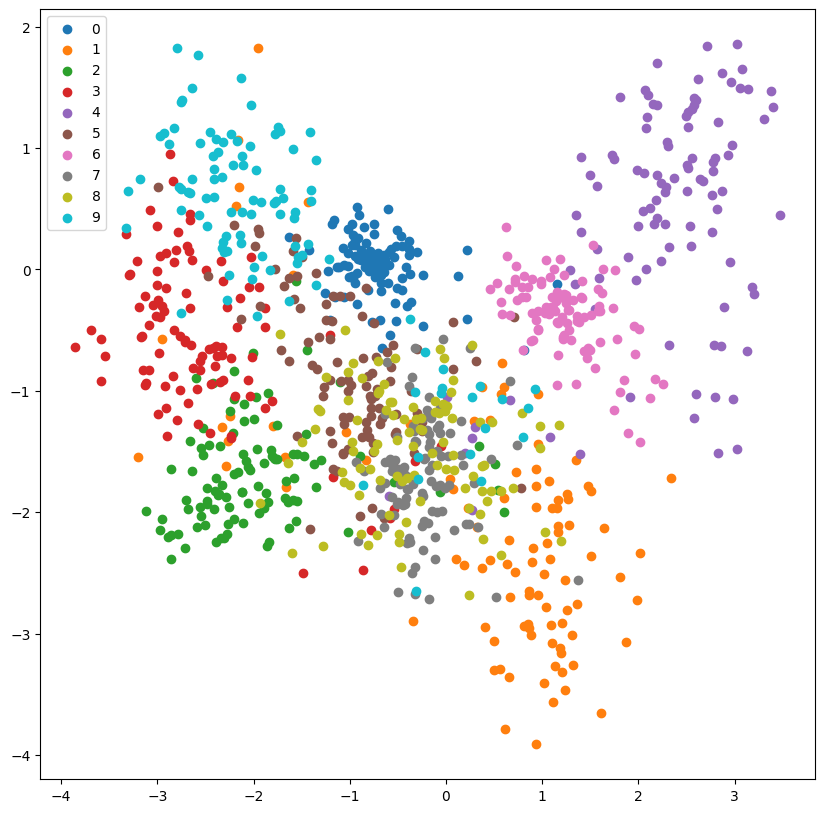

In [82]:
plt.figure(figsize=(10, 10))

for cl in range(10):
    lat_codes_class = lat_codes[labels == cl]
    plt.scatter(lat_codes_class[:, 0], lat_codes_class[:, 1], label=f"{cl}")

plt.legend()
plt.show()

### Карта средних изображений декодера

In [83]:
xx = torch.linspace(-1.2, 1.2, 10).to(device)
yy = torch.linspace(-1.2, 1.2, 10).to(device)

xm, ym = torch.meshgrid(xx, yy, indexing="ij")

In [84]:
z_vectors = torch.cat([xm.unsqueeze(2), ym.unsqueeze(2)], dim=2)
pred = model_vae.decode(z_vectors.view(-1, 2))
pred = pred.view(10, 10, 28, 28)

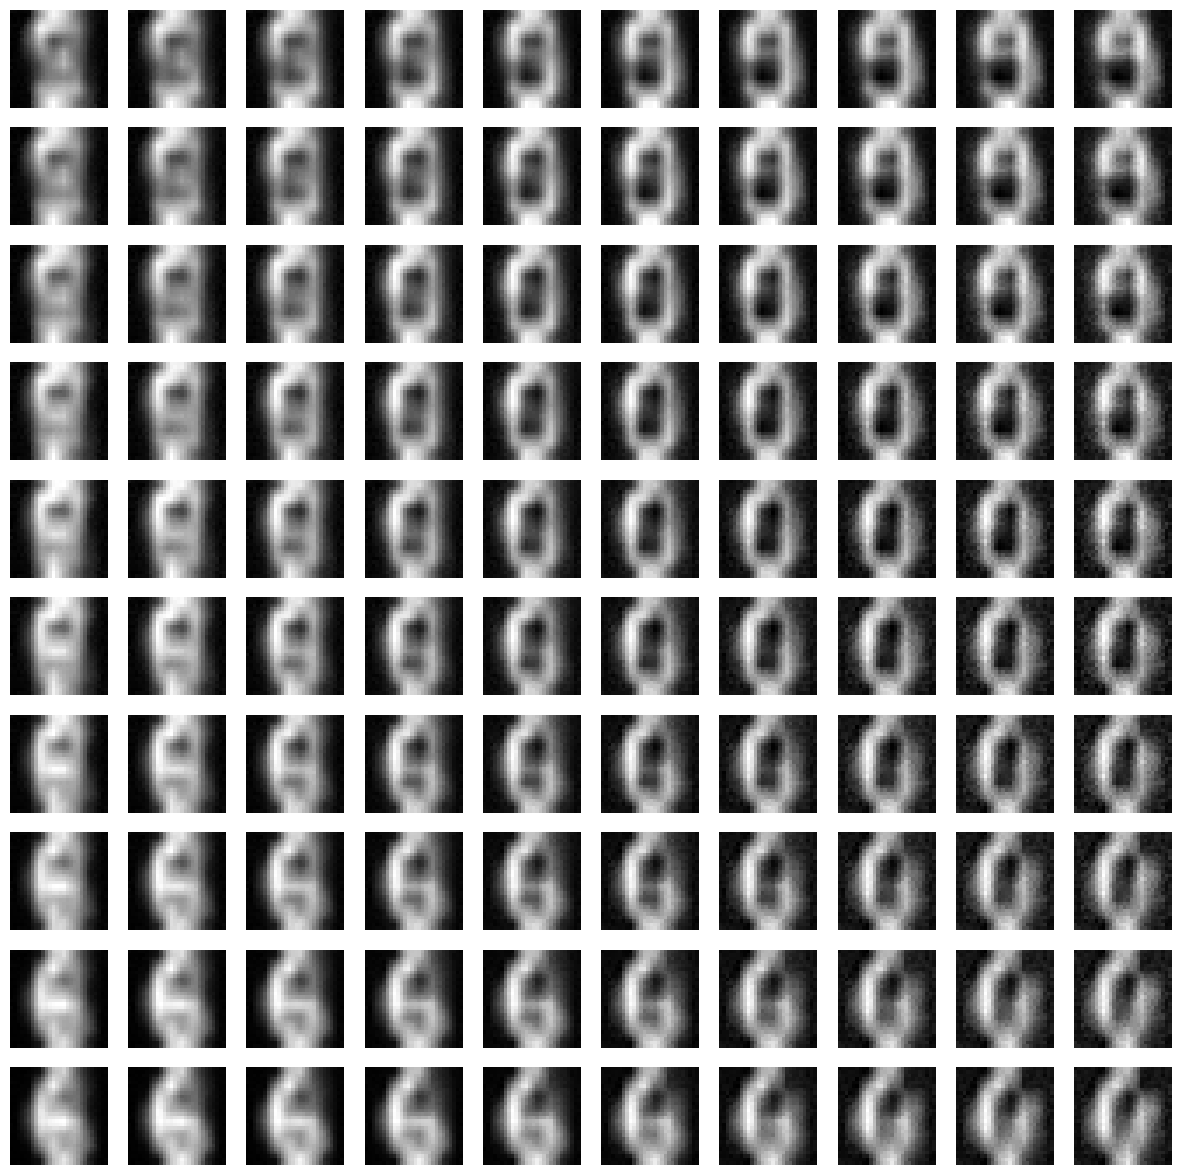

In [85]:
fig, axes = plt.subplots(10, 10, figsize=(15, 15))

for i in range(10):
    for j in range(10):
        axes[i, j].axis("off")
        axes[i, j].imshow(pred[i, j].cpu().detach().numpy(), cmap="gray")

### 5.3 Генерация из априорного распределения

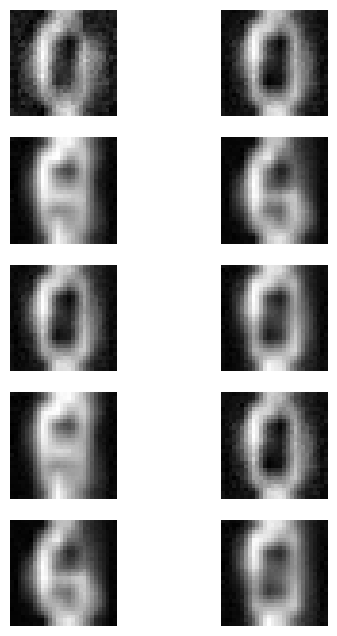

In [86]:
# create 10 samples from latent space and decode them
z = torch.randn(10, 2).to(device)
sampled_from_z = model_vae.decode(z)

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(5, 8))

for ax, sampled in zip(axs.flat, sampled_from_z):
    ax.imshow(sampled[0].cpu().detach().numpy(), cmap="gray")
    ax.axis("off")

## 6. Conditional VAE

Обе сети получают метку цифры $y$.

Возьмём общий для всех классов априорный закон $p(z\mid y)=\mathcal N(0,I)$.

После обучения зафиксируем один нормальный шум и переберём десять меток

In [87]:
class MNISTEncoder_cvae(nn.Module):
    def __init__(self, lat_size):
        super().__init__()

        self.lat_size = lat_size

        self.flatten = nn.Flatten()
        self.enc_net = nn.Sequential(nn.Linear(794, 512), nn.ReLU())

        self.mu = nn.Linear(512, self.lat_size)
        self.logvar = nn.Linear(512, self.lat_size)

    def forward(
        self, x: torch.Tensor, y: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        z = self.flatten(x)
        onehot_y = nn.functional.one_hot(y, 10)
        z = torch.cat([z, onehot_y], dim=1)
        z = self.enc_net(z)
        mu = self.mu(z)
        logvar = self.logvar(z)

        return mu, logvar


class MNISTDecoder_cvae(nn.Module):
    def __init__(self, lat_size: int) -> None:
        super().__init__()

        self.lat_size = lat_size

        self.dec_net = nn.Sequential(
            nn.Linear(self.lat_size + 10, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        onehot_y = nn.functional.one_hot(y, 10)
        z_cond = torch.cat([z, onehot_y], dim=1)

        x_reconstructed = self.dec_net(z_cond)
        x_reconstructed = x_reconstructed.view(-1, 1, 28, 28)

        return x_reconstructed

In [88]:
class ConditionalVariationalAutoEncoder(nn.Module):
    def __init__(
        self,
        lat_size: int,
        KL_weight: float = 1.0,
        encoder_class: Type[MNISTEncoder_cvae] = MNISTEncoder_cvae,
        decoder_class: Type[MNISTDecoder_cvae] = MNISTDecoder_cvae,
        criterion_class: Type[nn.MSELoss] = nn.MSELoss,
    ) -> None:
        super().__init__()

        self.lat_size = lat_size
        self.enc = encoder_class(lat_size)
        self.dec = decoder_class(lat_size)

        self.criterion = criterion_class()

        
        self.KL_weight = KL_weight

    def encode(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        return self.enc(x, y)

    def decode(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        return self.dec(z, y)

    def sample_z(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        eps = torch.randn(mu.size()).to(mu.device)

        return mu + torch.exp(logvar / 2) * eps

    def custom_loss(
        self,
        x: torch.Tensor,
        reconstructed_x: torch.Tensor,
        mu: torch.Tensor,
        logvar: torch.Tensor,
    ) -> torch.Tensor:
        KL = torch.mean(
            -0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp(), dim=1), dim=0
        )
        reconstruction_loss = ((x - reconstructed_x).flatten(1).square().sum(1) / (2 * 0.25)).mean()

        return KL * self.KL_weight + reconstruction_loss

    def compute_loss(
        self, x: torch.Tensor, y: torch.Tensor, return_reconstruction: bool = False
    ) -> Union[tuple[torch.Tensor, torch.Tensor], torch.Tensor]:
        mu, logvar = self.encode(x, y)
        z = self.sample_z(mu, logvar)
        reconstructed_x = self.decode(z, y)

        loss = self.custom_loss(x, reconstructed_x, mu, logvar)

        if return_reconstruction:
            return loss, reconstructed_x
        else:
            return loss

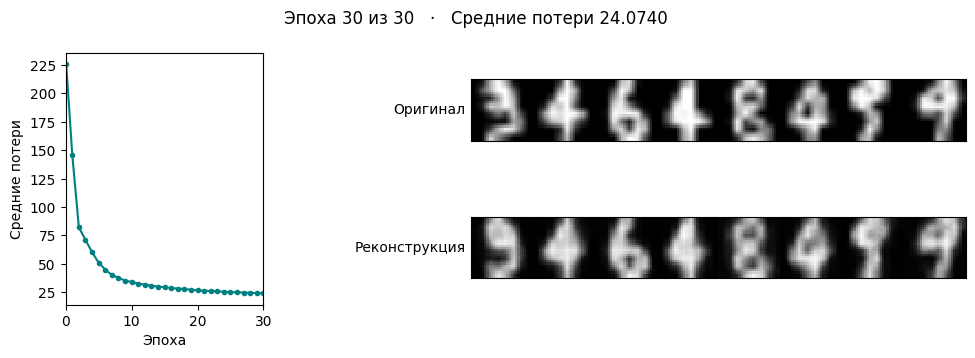

In [95]:
hidden_dim = 8
model_cvae = ConditionalVariationalAutoEncoder(hidden_dim).to(device)
optimizer = optim.Adam(model_cvae.parameters(), lr=1e-3)

train_model(model_cvae, train_dataloader, optimizer, conditional=True)

In [96]:
z = torch.randn(1, hidden_dim, device=device).expand(10, -1)
y = torch.arange(10).to(device)

sampled_from_z = model_cvae.decode(z, y)

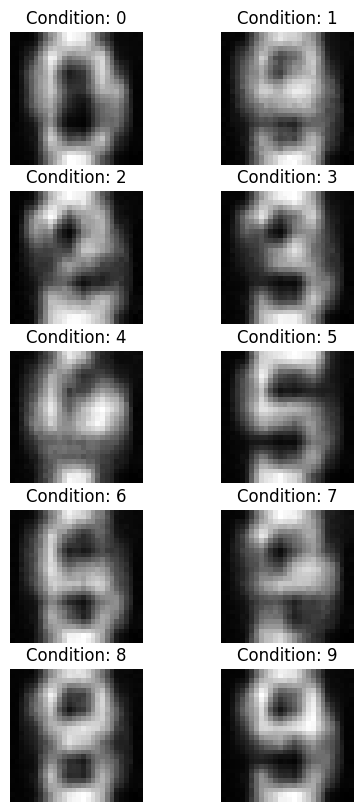

In [97]:
fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(5, 10))

for ax, sampled, label in zip(axs.flat, sampled_from_z, y):
    ax.imshow(sampled[0].cpu().detach().numpy(), cmap="gray")
    ax.set_title(f"Condition: {label}")
    ax.axis("off")

In [99]:
def get_latent_codes_and_labels_cvae(
    dataloader: torch.utils.data.DataLoader, model: nn.Module, num_objects: int
) -> tuple[torch.Tensor, torch.Tensor]:
    lat_codes = torch.empty((0, model.lat_size)).to(device)
    labels = torch.empty(0).to(device)

    for batch in dataloader:
        x, y = batch
        x, y = x.to(device), y.to(device)
        cur_lat_mean, cur_lat_var = model.encode(x, y)

        eps = torch.randn(cur_lat_mean.shape).to(device)
        cur_lat_codes = cur_lat_mean + torch.exp(cur_lat_var / 2) * eps

        lat_codes = torch.cat((lat_codes, cur_lat_codes), dim=0)
        labels = torch.cat((labels, y), dim=0)

        if lat_codes.shape[0] >= num_objects:
            break
    lat_codes = lat_codes[:num_objects].detach().cpu().numpy()
    labels = labels[:num_objects].detach().cpu().numpy()

    return lat_codes, labels

In [100]:
lat_codes, labels = get_latent_codes_and_labels_cvae(train_dataloader, model_cvae, 1000)

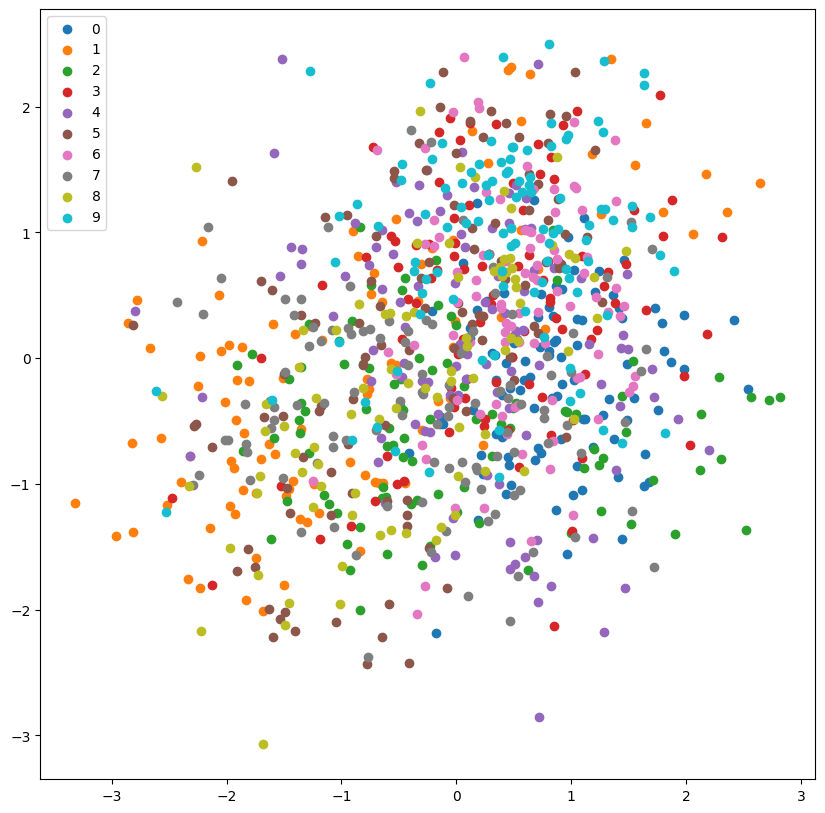

In [101]:
plt.figure(figsize=(10, 10))

for cl in range(10):
    lat_codes_class = lat_codes[labels == cl]
    plt.scatter(lat_codes_class[:, 0], lat_codes_class[:, 1], label=f"{cl}")

plt.legend()
plt.show()

Статьи с помощью которых реализованы последние 2 секции, довольно подробно поясняющие, что происходит:

* [**VAE**](https://wiseodd.github.io/techblog/2016/12/10/variational-autoencoder/)
* [**Conditional VAE**](https://wiseodd.github.io/techblog/2016/12/17/conditional-vae/)